# CSC 4254: Computer Vision & Pattern Recognition — Mid Assignment
## Custom Convolutional Neural Network (CNN) for Multi-Class Image Classification
- **Student Name:** Md. Sabit Bin Arif
- **Student ID:** [Your Student ID]
- **Dataset:** CIFAR-10 (10 distinct object classes, 60,000 RGB images)

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchsummary import summary
from sklearn.metrics import classification_report, confusion_matrix

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

# Configure device (Automatically uses GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda



Number of Classes: 10
Class Names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Total Pre-Split Training Images: 50000
Total Testing Images: 10000


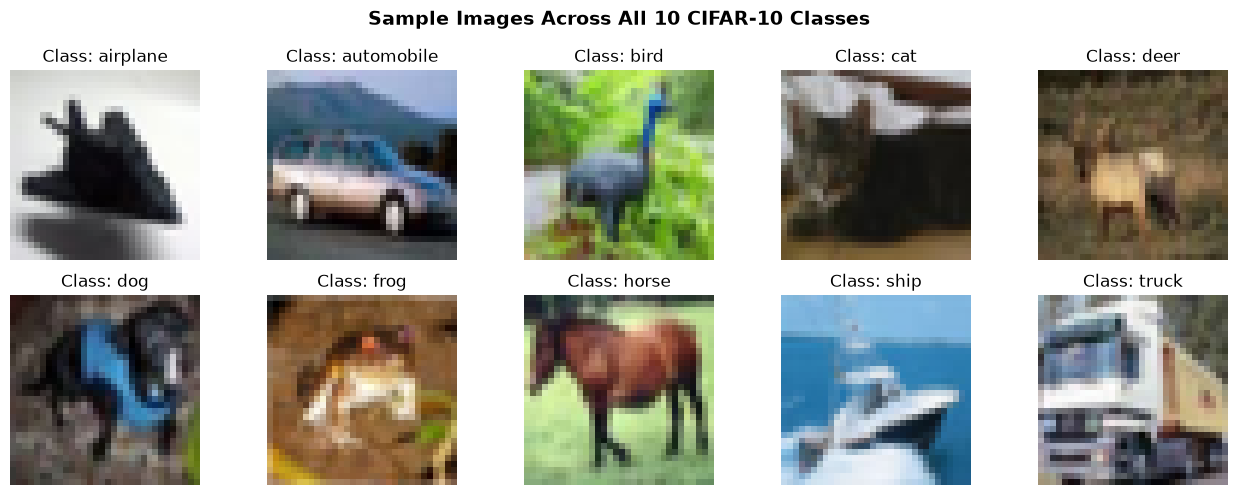

In [2]:
# CIFAR-10 automatically downloads into './data' on first run
raw_train = datasets.CIFAR10(root='./data', train=True, download=True)
raw_test = datasets.CIFAR10(root='./data', train=False, download=True)
class_names = raw_train.classes

print(f"\nNumber of Classes: {len(class_names)}")
print(f"Class Names: {class_names}")
print(f"Total Pre-Split Training Images: {len(raw_train)}")
print(f"Total Testing Images: {len(raw_test)}")

# Visualize 10 sample images (one from each class)
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
fig.suptitle("Sample Images Across All 10 CIFAR-10 Classes", fontsize=14, fontweight='bold')

shown_classes = set()
idx = 0
while len(shown_classes) < 10:
    img, label = raw_train[idx]
    if label not in shown_classes:
        shown_classes.add(label)
        ax = axes[label // 5, label % 5]
        ax.imshow(img)
        ax.set_title(f"Class: {class_names[label]}")
        ax.axis("off")
    idx += 1

plt.tight_layout()
plt.savefig("sample_images.png", dpi=150)
plt.show()

In [3]:
# Hyperparameters for Data Loading
BATCH_SIZE = 64
VAL_SPLIT = 0.2  # 80% Train (40,000), 20% Validation (10,000)

# Data augmentation applied ONLY to the training set to prevent overfitting
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.2470, 0.2435, 0.2616))
])

# Deterministic normalization only for Validation and Test sets
val_test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.2470, 0.2435, 0.2616))
])

# Load datasets and create Train/Val split
full_train_augmented = datasets.CIFAR10(root='./data', train=True, download=False, transform=train_transforms)
full_train_clean = datasets.CIFAR10(root='./data', train=True, download=False, transform=val_test_transforms)

val_size = int(len(full_train_augmented) * VAL_SPLIT)
train_size = len(full_train_augmented) - val_size

generator = torch.Generator().manual_seed(42)
train_subset, _ = random_split(full_train_augmented, [train_size, val_size], generator=generator)

generator = torch.Generator().manual_seed(42)
_, val_subset = random_split(full_train_clean, [train_size, val_size], generator=generator)

test_dataset = datasets.CIFAR10(root='./data', train=False, download=False, transform=val_test_transforms)

# Create DataLoaders (num_workers=0 ensures smooth compatibility on Windows/macOS in VS Code)
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"\nDataLoaders Ready -> Train: {len(train_subset)} | Val: {len(val_subset)} | Test: {len(test_dataset)}")


DataLoaders Ready -> Train: 40000 | Val: 10000 | Test: 10000


In [4]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(CustomCNN, self).__init__()
        
        # Feature Extractor: 3 Convolutional Blocks with BatchNorm, ReLU, and MaxPool
        self.features = nn.Sequential(
            # Block 1: (3, 32, 32) -> (32, 16, 16)
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 2: (32, 16, 16) -> (64, 8, 8)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 3: (64, 8, 8) -> (128, 4, 4)
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Classifier: Fully Connected Layers with Dropout Regularization
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(256, num_classes)  # Raw logits output for nn.CrossEntropyLoss
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = CustomCNN(num_classes=len(class_names)).to(device)
print("\n--- Model Architecture Summary ---")
summary(model, input_size=(3, 32, 32))


--- Model Architecture Summary ---


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 32, 32]             896
       BatchNorm2d-2           [-1, 32, 32, 32]              64
              ReLU-3           [-1, 32, 32, 32]               0
            Conv2d-4           [-1, 32, 32, 32]           9,248
       BatchNorm2d-5           [-1, 32, 32, 32]              64
              ReLU-6           [-1, 32, 32, 32]               0
         MaxPool2d-7           [-1, 32, 16, 16]               0
            Conv2d-8           [-1, 64, 16, 16]          18,496
       BatchNorm2d-9           [-1, 64, 16, 16]             128
             ReLU-10           [-1, 64, 16, 16]               0
           Conv2d-11           [-1, 64, 16, 16]          36,928
      BatchNorm2d-12           [-1, 64, 16, 16]             128
             ReLU-13           [-1, 64, 16, 16]               0
        MaxPool2d-14             [-1, 6

In [5]:
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
EPOCHS = 15
MODEL_SAVE_PATH = "best_custom_cnn.pth"

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0

print("\n--- Starting Training ---")
for epoch in range(EPOCHS):
    # Training Phase
    model.train()
    running_train_loss, correct_train, total_train = 0.0, 0, 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_train_loss / total_train
    epoch_train_acc = 100.0 * correct_train / total_train
    
    # Validation Phase
    model.eval()
    running_val_loss, correct_val, total_val = 0.0, 0, 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = running_val_loss / total_val
    epoch_val_acc = 100.0 * correct_val / total_val
    
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    
    # Checkpoint best model weights
    saved_msg = ""
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        saved_msg = "--> Saved Best Model"
        
    print(f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] | "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}% {saved_msg}")

model_size_mb = os.path.getsize(MODEL_SAVE_PATH) / (1024 * 1024)
print(f"\nTraining Complete! Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Saved Model File: '{MODEL_SAVE_PATH}' ({model_size_mb:.2f} MB - Safe to upload to GitHub!)")


--- Starting Training ---


Epoch [01/15] | Train Loss: 1.6012, Train Acc: 40.53% | Val Loss: 1.2780, Val Acc: 53.99% --> Saved Best Model


Epoch [02/15] | Train Loss: 1.2591, Train Acc: 54.52% | Val Loss: 1.1065, Val Acc: 60.48% --> Saved Best Model


Epoch [03/15] | Train Loss: 1.1089, Train Acc: 60.62% | Val Loss: 0.8933, Val Acc: 67.52% --> Saved Best Model


Epoch [04/15] | Train Loss: 1.0030, Train Acc: 64.83% | Val Loss: 0.8429, Val Acc: 69.91% --> Saved Best Model


Epoch [05/15] | Train Loss: 0.9297, Train Acc: 67.23% | Val Loss: 0.7850, Val Acc: 72.15% --> Saved Best Model


... (6 outputs left out)

Epoch [12/15] | Train Loss: 0.6713, Train Acc: 77.72% | Val Loss: 0.5675, Val Acc: 80.66% --> Saved Best Model


Epoch [13/15] | Train Loss: 0.6371, Train Acc: 78.82% | Val Loss: 0.5888, Val Acc: 80.04% 


Epoch [14/15] | Train Loss: 0.6135, Train Acc: 79.86% | Val Loss: 0.5448, Val Acc: 81.37% --> Saved Best Model


Epoch [15/15] | Train Loss: 0.5891, Train Acc: 80.25% | Val Loss: 0.4960, Val Acc: 83.01% --> Saved Best Model

Training Complete! Best Validation Accuracy: 83.01%
Saved Model File: 'best_custom_cnn.pth' (2.56 MB - Safe to upload to GitHub!)



Final Test Set Accuracy: 82.86%

Detailed Classification Report:
              precision    recall  f1-score   support

    airplane       0.82      0.85      0.83      1000
  automobile       0.94      0.93      0.94      1000
        bird       0.76      0.73      0.74      1000
         cat       0.74      0.66      0.70      1000
        deer       0.71      0.91      0.80      1000
         dog       0.76      0.76      0.76      1000
        frog       0.88      0.86      0.87      1000
       horse       0.91      0.82      0.86      1000
        ship       0.93      0.86      0.89      1000
       truck       0.89      0.90      0.89      1000

    accuracy                           0.83     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.83      0.83      0.83     10000



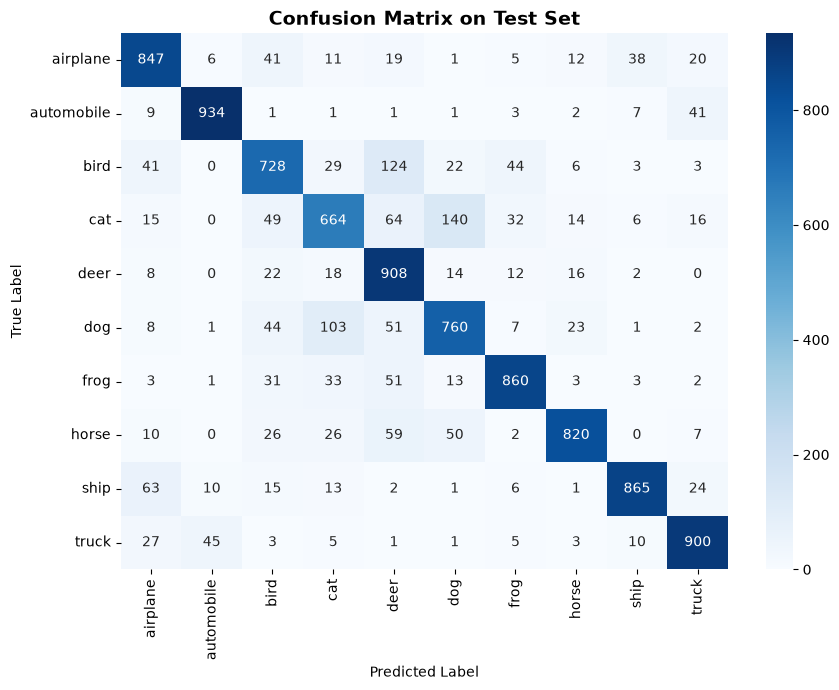

In [6]:
best_model = CustomCNN(num_classes=len(class_names)).to(device)
best_model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=device))
best_model.eval()

all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = best_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = 100.0 * np.mean(np.array(all_preds) == np.array(all_labels))
print(f"\n==========================================")
print(f"Final Test Set Accuracy: {test_acc:.2f}%")
print(f"==========================================\n")

print("Detailed Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Plot & Save Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix on Test Set", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

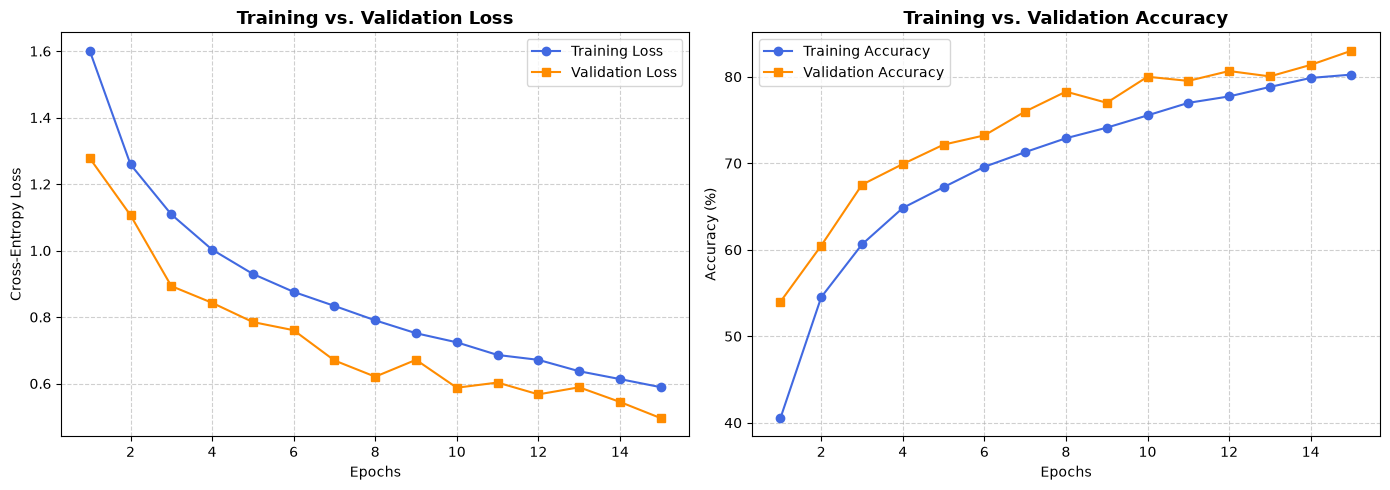

In [7]:
epochs_range = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, history['train_loss'], label='Training Loss', marker='o', color='royalblue')
ax1.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='s', color='darkorange')
ax1.set_title('Training vs. Validation Loss', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(epochs_range, history['train_acc'], label='Training Accuracy', marker='o', color='royalblue')
ax2.plot(epochs_range, history['val_acc'], label='Validation Accuracy', marker='s', color='darkorange')
ax2.set_title('Training vs. Validation Accuracy', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()